# Лабораторное занятие №6
## Python, знакомство с библиотеками

**Выполнил:** Полупанов В. Д.
**Группа:** ПИ-311

**Цель работы:** изучить принцип подключения сторонних библиотек в Python и
научиться применять их для визуализации данных, статистического анализа и
математических расчётов на примере `matplotlib`, `numpy`, `scikit-learn` и `math`.

**Задачи:**
1. Повторить обзорный пример: перевод градусов Цельсия в Фаренгейты и построение
   графика, линейная регрессия, прогнозирование.
2. Выполнить задания обычной сложности (5 шт.).
3. Выполнить задания повышенной сложности (рисунок фигуры средствами
   `matplotlib` и разбор датасета Fashion-MNIST).

---
## 1. Обзорная часть: Цельсий → Фаренгейт


In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression

# dataset: градусы Цельсия и соответствующие им градусы Фаренгейта
celsius = [[-67.0], [-34.0], [0], [34.0], [54.0], [67.0], [100]]
fahrenheit = [[-88.6], [-29.2], [32.0], [93.2], [129.2], [152.6], [212.0]]

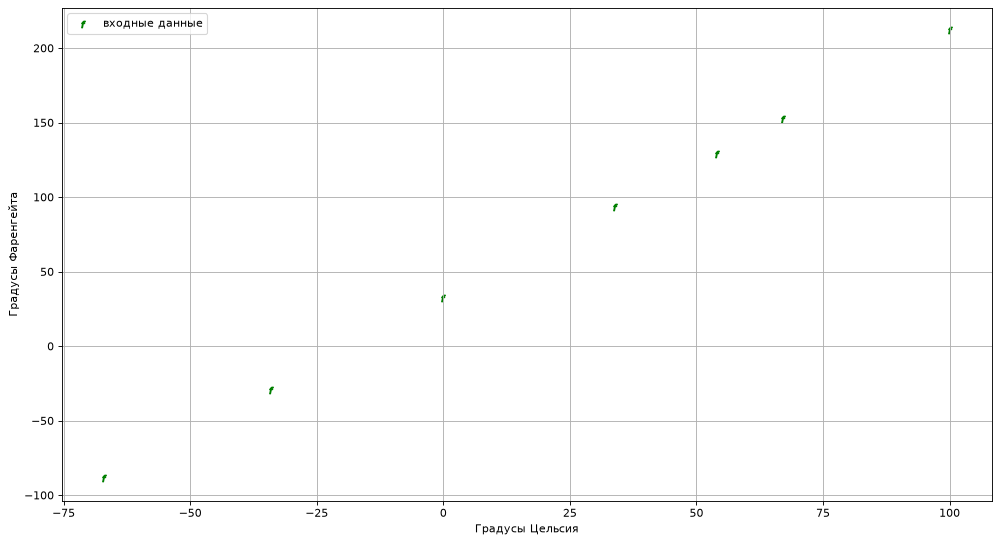

In [2]:
# визуализация исходных данных
plt.figure(figsize=(15, 8), dpi=80)
plt.scatter(celsius, fahrenheit, label='входные данные', color='green', marker='$f$')
plt.xlabel('Градусы Цельсия')
plt.ylabel('Градусы Фаренгейта')
plt.legend()
plt.grid(True)
plt.show()

In [3]:
# вывод исходных данных в консоль
for c, f in zip(celsius, fahrenheit):
    print(f'Цельсий {c[0]:>6} = Фаренгейт {f[0]:>6}')

Цельсий  -67.0 = Фаренгейт  -88.6
Цельсий  -34.0 = Фаренгейт  -29.2
Цельсий      0 = Фаренгейт   32.0
Цельсий   34.0 = Фаренгейт   93.2
Цельсий   54.0 = Фаренгейт  129.2
Цельсий   67.0 = Фаренгейт  152.6
Цельсий    100 = Фаренгейт  212.0


In [4]:
# обучение линейной регрессии
lr = LinearRegression()
lr.fit(celsius, fahrenheit)

print('Коэффициент (coef_):', lr.coef_[0][0])
print('Свободный член (intercept_):', lr.intercept_[0])
print('Проверка: 256 C ->', lr.predict([[256]])[0][0], 'F')
print('Проверка: 123 C ->', lr.predict([[123]])[0][0], 'F')

Коэффициент (coef_): 1.8000000000000007
Свободный член (intercept_): 31.99999999999998
Проверка: 256 C -> 492.8000000000002 F
Проверка: 123 C -> 253.40000000000006 F


In [5]:
# прогноз для новых значений и его сравнение с эталонной формулой
celsius_test = [[-50], [10], [30], [20], [10], [70], [87]]
fahrenheit_test = lr.predict(celsius_test)

for c, f in zip(celsius_test, fahrenheit_test):
    print(f'Цельсий {c[0]:>4} -> прогноз {f[0]:8.2f} F | по формуле {c[0] * 1.8 + 32:8.2f} F')

Цельсий  -50 -> прогноз   -58.00 F | по формуле   -58.00 F
Цельсий   10 -> прогноз    50.00 F | по формуле    50.00 F
Цельсий   30 -> прогноз    86.00 F | по формуле    86.00 F
Цельсий   20 -> прогноз    68.00 F | по формуле    68.00 F
Цельсий   10 -> прогноз    50.00 F | по формуле    50.00 F
Цельсий   70 -> прогноз   158.00 F | по формуле   158.00 F
Цельсий   87 -> прогноз   188.60 F | по формуле   188.60 F


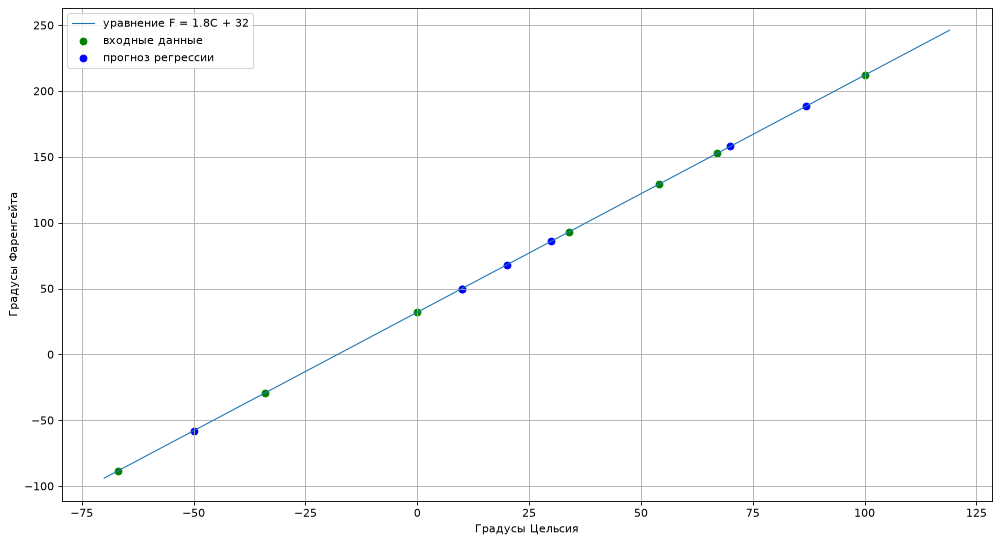

In [6]:
# точное соотношение через numpy
x_range = np.arange(-70, 120)
y_range = x_range * 1.8 + 32

plt.figure(figsize=(15, 8), dpi=80)
plt.plot(x_range, y_range, label='уравнение F = 1.8C + 32', linewidth=1)
plt.scatter(celsius, fahrenheit, label='входные данные', color='green')
plt.scatter(celsius_test, fahrenheit_test, label='прогноз регрессии', color='blue')
plt.xlabel('Градусы Цельсия')
plt.ylabel('Градусы Фаренгейта')
plt.legend()
plt.grid(True)
plt.show()

**Вывод.** Линейная регрессия восстановила зависимость `F = 1.8·C + 32`
(коэффициент ≈ 1.8, свободный член ≈ 32), поэтому прогноз совпадает с точной
формулой. Модель не знает физики перевода — она вывела линейную зависимость из
самих данных.

---
## 2. Задания обычной сложности

### Задание 1. Фаренгейты → Кельвины
Возьмём систему мер «Фаренгейт — Кельвин» и проделаем те же операции.
Стартовые данные вычислим по формуле `K = (F − 32) / 1.8 + 273.15`, затем
натренируем регрессию и сравним прогноз с формулой.


In [7]:
# стартовые данные: одинаковые температуры, выраженные в F и в K
fahrenheit = [[-88.6], [-29.2], [32.0], [93.2], [129.2], [152.6], [212.0]]
kelvin = [[(f[0] - 32) / 1.8 + 273.15] for f in fahrenheit]

for f, k in zip(fahrenheit, kelvin):
    print(f'Фаренгейт {f[0]:>7} = Кельвин {k[0]:8.2f}')

Фаренгейт   -88.6 = Кельвин   206.15
Фаренгейт   -29.2 = Кельвин   239.15
Фаренгейт    32.0 = Кельвин   273.15
Фаренгейт    93.2 = Кельвин   307.15
Фаренгейт   129.2 = Кельвин   327.15
Фаренгейт   152.6 = Кельвин   340.15
Фаренгейт   212.0 = Кельвин   373.15


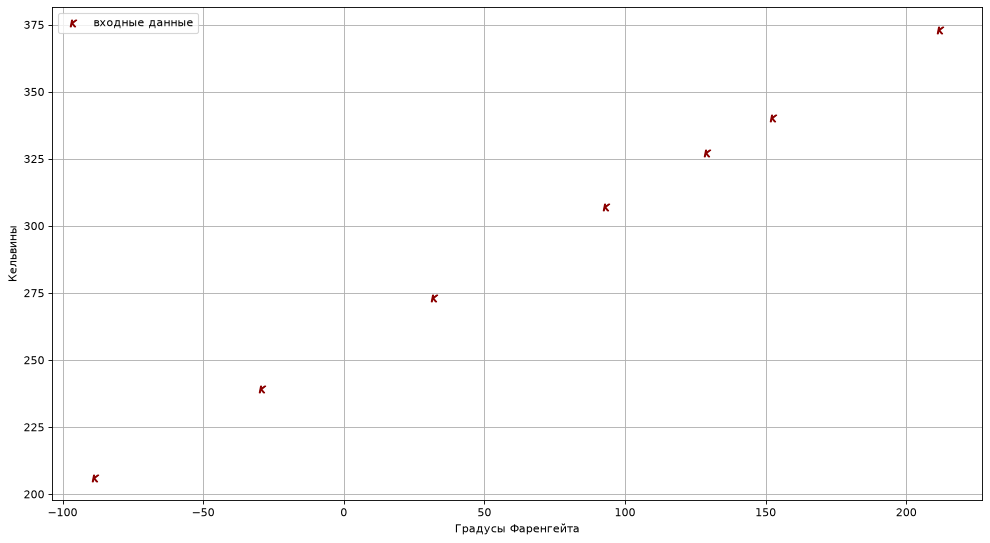

In [8]:
plt.figure(figsize=(15, 8), dpi=80)
plt.scatter(fahrenheit, kelvin, label='входные данные', color='darkred', marker='$K$')
plt.xlabel('Градусы Фаренгейта')
plt.ylabel('Кельвины')
plt.legend()
plt.grid(True)
plt.show()

In [9]:
lr_k = LinearRegression()
lr_k.fit(fahrenheit, kelvin)

print('Коэффициент (coef_):', lr_k.coef_[0][0])          # ожидаем 1/1.8 ~ 0.5556
print('Свободный член (intercept_):', lr_k.intercept_[0])  # ожидаем 255.37
print('Проверка: 500 F ->', lr_k.predict([[500]])[0][0], 'K')
print('Формула: 500 F ->', (500 - 32) / 1.8 + 273.15, 'K')

Коэффициент (coef_): 0.5555555555555555
Свободный член (intercept_): 255.37222222222226
Проверка: 500 F -> 533.15 K
Формула: 500 F -> 533.15 K


In [10]:
fahrenheit_test = [[-58], [50], [86], [68], [50], [158], [188.6]]
kelvin_test = lr_k.predict(fahrenheit_test)

for f, k in zip(fahrenheit_test, kelvin_test):
    formula = (f[0] - 32) / 1.8 + 273.15
    print(f'Фаренгейт {f[0]:>7} -> прогноз {k[0]:8.2f} K | по формуле {formula:8.2f} K')

Фаренгейт     -58 -> прогноз   223.15 K | по формуле   223.15 K
Фаренгейт      50 -> прогноз   283.15 K | по формуле   283.15 K
Фаренгейт      86 -> прогноз   303.15 K | по формуле   303.15 K
Фаренгейт      68 -> прогноз   293.15 K | по формуле   293.15 K
Фаренгейт      50 -> прогноз   283.15 K | по формуле   283.15 K
Фаренгейт     158 -> прогноз   343.15 K | по формуле   343.15 K
Фаренгейт   188.6 -> прогноз   360.15 K | по формуле   360.15 K


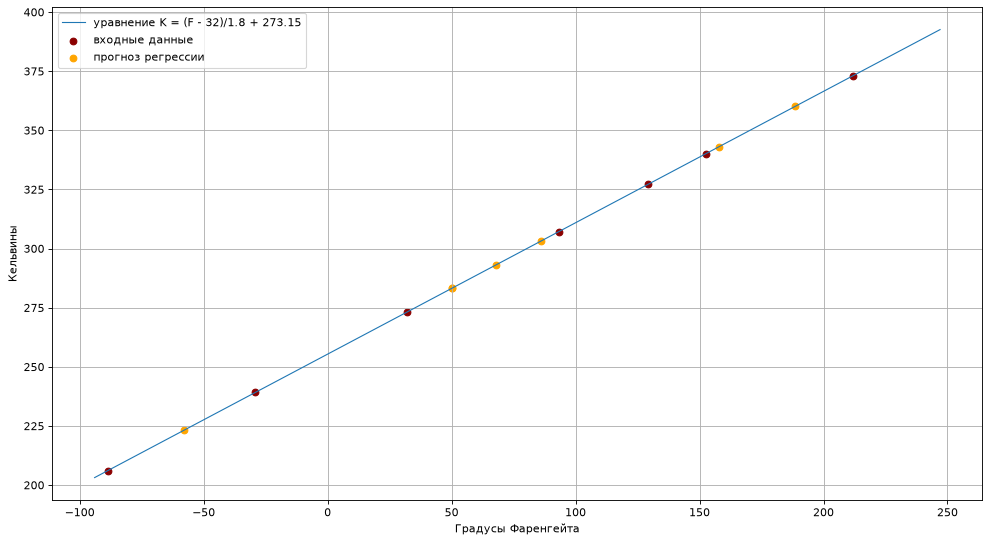

In [11]:
x_range = np.arange(-94, 248)
y_range = (x_range - 32) / 1.8 + 273.15

plt.figure(figsize=(15, 8), dpi=80)
plt.plot(x_range, y_range, label='уравнение K = (F - 32)/1.8 + 273.15', linewidth=1)
plt.scatter(fahrenheit, kelvin, label='входные данные', color='darkred')
plt.scatter(fahrenheit_test, kelvin_test, label='прогноз регрессии', color='orange')
plt.xlabel('Градусы Фаренгейта')
plt.ylabel('Кельвины')
plt.legend()
plt.grid(True)
plt.show()

### Задание 2. Загрузка репозитория GitHub в блокнот
Репозиторий, созданный в лабораторной работе №4:
`https://github.com/Resolveq-q/PolupanovVD-PI311.git`.

В Google Colab ячейка ниже клонирует его внутрь среды выполнения. Локально
(в Jupyter/PyCharm) команда `!git clone` тоже работает при наличии Git.


In [12]:
# клонирование репозитория (в Colab раскомментировать; повторный запуск не нужен)
# !git clone https://github.com/Resolveq-q/PolupanovVD-PI311.git
# !ls PolupanovVD-PI311

### Задание 3. Три типа графиков, не рассматривавшихся в работе
Использованы: **столбчатая диаграмма** (`bar`), **круговая диаграмма** (`pie`)
и **гистограмма** (`hist`). Дополнительно — `boxplot`, показывающий
распределение ряда чисел.


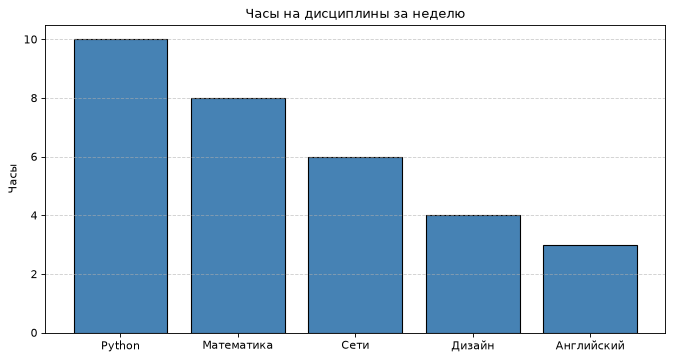

In [13]:
# 1) столбчатая диаграмма — часы, отведённые на предметы за неделю
subjects = ['Python', 'Математика', 'Сети', 'Дизайн', 'Английский']
hours = [10, 8, 6, 4, 3]

plt.figure(figsize=(10, 5), dpi=80)
plt.bar(subjects, hours, color='steelblue', edgecolor='black')
plt.title('Часы на дисциплины за неделю')
plt.ylabel('Часы')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

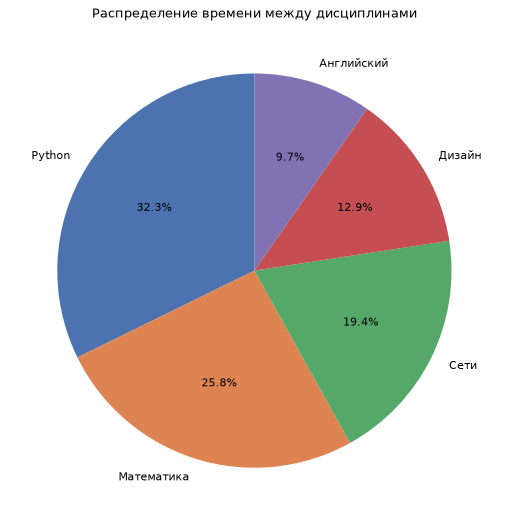

In [14]:
# 2) круговая диаграмма — доли тех же дисциплин
plt.figure(figsize=(8, 8), dpi=80)
plt.pie(hours, labels=subjects, autopct='%1.1f%%', startangle=90,
        colors=['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B3'])
plt.title('Распределение времени между дисциплинами')
plt.show()

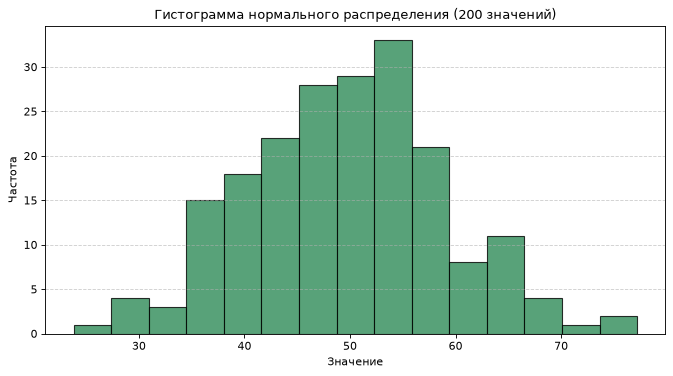

In [15]:
# 3) гистограмма — распределение 200 случайных значений вокруг 50
np.random.seed(42)
data = np.random.normal(50, 10, 200)

plt.figure(figsize=(10, 5), dpi=80)
plt.hist(data, bins=15, color='seagreen', edgecolor='black', alpha=0.8)
plt.title('Гистограмма нормального распределения (200 значений)')
plt.xlabel('Значение')
plt.ylabel('Частота')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

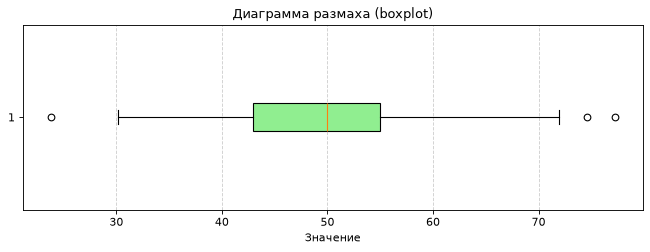

In [16]:
# 4) дополнительно — «ящик с усами» для тех же данных
plt.figure(figsize=(10, 3), dpi=80)
plt.boxplot(data, orientation='horizontal', patch_artist=True,
            boxprops=dict(facecolor='lightgreen'))
plt.title('Диаграмма размаха (boxplot)')
plt.xlabel('Значение')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.show()

### Задание 4. Библиотека `math`: Эйлер, Пи, nan, факториал
Порядковый номер в журнале — **1**, память телефона — **128 ГБ**.


In [17]:
import math

n = 1      # порядковый номер в журнале
mem = 128   # объём памяти телефона, ГБ

print('Число Эйлера (math.e)  :', math.e)
print('Число Пи (math.pi)     :', math.pi)
print('Не число (math.nan)    :', math.nan)
print('Факториал от номера в журнале ' + str(n) + '! :', math.factorial(n))

# наибольший делитель для двух чисел: номера в журнале и памяти телефона
print('НОД(' + str(n) + ', ' + str(mem) + ') =', math.gcd(n, mem))

Число Эйлера (math.e)  : 2.718281828459045
Число Пи (math.pi)     : 3.141592653589793
Не число (math.nan)    : nan
Факториал от номера в журнале 1! : 1
НОД(1, 128) = 1


### Задание 5. Наибольший общий делитель (номер в журнале и память телефона)
Подробный разбор: помимо готовой `math.gcd` реализуем алгоритм Евклида вручную,
чтобы показать принцип работы.


In [18]:
def gcd_euclid(a, b):
    """Наибольший общий делитель алгоритмом Евклида."""
    while b:
        a, b = b, a % b
    return a

a, b = 1, 128
print('НОД через math.gcd     :', math.gcd(a, b))
print('НОД алгоритмом Евклида :', gcd_euclid(a, b))
print('Проверка: наибольший делитель числа', a, 'не больше', a,
      ', а делителей у', a, 'всего', sum(1 for d in range(1, a + 1) if a % d == 0))

НОД через math.gcd     : 1
НОД алгоритмом Евклида : 1
Проверка: наибольший делитель числа 1 не больше 1 , а делителей у 1 всего 1


---
## 3. Задания повышенной сложности

### 3.1 Рисунок средствами `matplotlib`
Фигура собрана из простых примитивов: `Circle`, `Ellipse`, `Polygon`,
`Rectangle` и дуги. Такой приём показывает, что `matplotlib` — это не только
«графики», но и универсальный инструмент векторной графики.


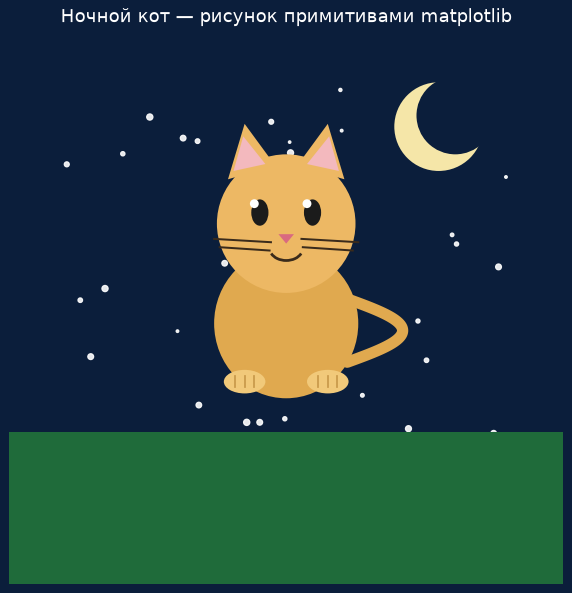

In [19]:
from matplotlib.patches import Circle, Ellipse, Polygon, Rectangle, Arc, Wedge

fig, ax = plt.subplots(figsize=(8, 8), dpi=90)

# ночное небо
ax.add_patch(Rectangle((-10, -10), 20, 20, facecolor='#0B1E3B', zorder=0))

# луна
ax.add_patch(Circle((5.5, 6.5), 1.6, facecolor='#F5E6A8', zorder=1))
ax.add_patch(Circle((6.1, 6.9), 1.4, facecolor='#0B1E3B', zorder=2))  # серп

# звёзды
rng = np.random.default_rng(7)
stars = rng.uniform(-8, 8, size=(45, 2))
ax.scatter(stars[:, 0], stars[:, 1], s=rng.uniform(4, 26, 45),
           color='white', zorder=1, alpha=0.9)

# трава
ax.add_patch(Rectangle((-10, -10), 20, 5.5, facecolor='#1F6B3A', zorder=2))

# тело кота
ax.add_patch(Ellipse((0, -0.6), 5.2, 5.4, facecolor='#E0A94F', zorder=3))
# голова
ax.add_patch(Circle((0, 3.0), 2.5, facecolor='#EDB864', zorder=4))
# уши
ax.add_patch(Polygon([[-2.1, 4.6], [-1.5, 6.6], [-0.4, 5.1]], closed=True,
                     facecolor='#EDB864', zorder=4))
ax.add_patch(Polygon([[2.1, 4.6], [1.5, 6.6], [0.4, 5.1]], closed=True,
                     facecolor='#EDB864', zorder=4))
ax.add_patch(Polygon([[-1.9, 4.9], [-1.55, 6.15], [-0.75, 5.15]], closed=True,
                     facecolor='#F3B9BE', zorder=5))
ax.add_patch(Polygon([[1.9, 4.9], [1.55, 6.15], [0.75, 5.15]], closed=True,
                     facecolor='#F3B9BE', zorder=5))

# глаза
ax.add_patch(Ellipse((-0.95, 3.4), 0.62, 0.95, facecolor='#1B1B1B', zorder=6))
ax.add_patch(Ellipse((0.95, 3.4), 0.62, 0.95, facecolor='#1B1B1B', zorder=6))
ax.add_patch(Circle((-1.15, 3.72), 0.16, facecolor='white', zorder=7))
ax.add_patch(Circle((0.75, 3.72), 0.16, facecolor='white', zorder=7))

# нос и рот
ax.add_patch(Polygon([[-0.28, 2.62], [0.28, 2.62], [0, 2.28]], closed=True,
                     facecolor='#D96A80', zorder=6))
ax.add_patch(Arc((0, 2.12), 1.2, 0.9, theta1=200, theta2=340,
                 edgecolor='#3A2B1B', linewidth=2.2, zorder=6))
# усы
for dy, xs in [(2.45, (-2.6, -0.55)), (2.15, (-2.4, -0.6)),
               (2.45, (0.55, 2.6)), (2.15, (0.6, 2.4))]:
    ax.plot(list(xs), [dy, dy - 0.12], color='#3A2B1B', linewidth=1.6, zorder=6)

# лапки
for x in (-1.5, 1.5):
    ax.add_patch(Ellipse((x, -2.7), 1.5, 0.85, facecolor='#F1C97A', zorder=5))
    for toe in (-0.35, 0, 0.35):
        ax.plot([x + toe, x + toe], [-2.5, -2.9], color='#C99A4B', linewidth=1.4, zorder=6)

# хвост
t = np.linspace(0, 1, 120)
tail_x = 2.2 + 2.0 * np.sin(t * np.pi * 1.4)
tail_y = -2.0 + 3.2 * t
ax.plot(tail_x, tail_y, color='#E0A94F', linewidth=9, solid_capstyle='round', zorder=3)

ax.set_xlim(-10, 10)
ax.set_ylim(-10, 10)
ax.set_aspect('equal')
ax.axis('off')
ax.set_title('Ночной кот — рисунок примитивами matplotlib', color='white', fontsize=14)
fig.patch.set_facecolor('#0B1E3B')
plt.show()

### 3.2 Fashion-MNIST
Fashion-MNIST — набор изображений одежды 28×28 в градациях серого, 10 классов,
по 6000 обучающих и 1000 тестовых примеров на класс. Это «замена» MNIST для
задач классификации.

Использованные библиотеки:
- **`tensorflow.keras`** — загрузка готового датасета `fashion_mnist` и построение
  полносвязной нейронной сети;
- **`matplotlib`** — визуализация примеров и графиков обучения;
- **`numpy`** —преобразование массивов: нормализация значений пикселей и
  однозначное кодирование меток;
- **`sklearn.metrics`** — `classification_report`, `confusion_matrix` — метрики
  качества классификации.

> В Google Colab ячейки выполняются сразу. Локально требуется установить
> `tensorflow`. Если он недоступен, ячейки помечают это и не прерывают ноутбук.


In [20]:
# проверка наличия tensorflow (в Colab установлен по умолчанию)
try:
    import tensorflow as tf
    from tensorflow.keras import layers, models
    from tensorflow.keras.datasets import fashion_mnist
    HAS_TF = True
except Exception as exc:  # noqa: BLE001
    HAS_TF = False
    print('TensorFlow не установлен:', exc)
    print('Установка: pip install tensorflow')

print('TensorFlow:', tf.__version__ if HAS_TF else 'нет')

TensorFlow: 2.21.0


In [21]:
if HAS_TF:
    (x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()
    print('Обучающая выборка:', x_train.shape, y_train.shape)
    print('Тестовая выборка  :', x_test.shape, y_test.shape)

    0/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 3us/step


       0/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   16384/26421880 ━━━━━━━━━━━━━━━━━━━━ 1:45 4us/step

   32768/26421880 ━━━━━━━━━━━━━━━━━━━━ 1:40 4us/step

   57344/26421880 ━━━━━━━━━━━━━━━━━━━━ 1:26 3us/step

... (591 outputs left out)

4349952/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step

4366336/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step

4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 9s 2us/step


Обучающая выборка: (60000, 28, 28) (60000,)
Тестовая выборка  : (10000, 28, 28) (10000,)


#### Все типы вещей, которые распознаёт сеть

In [22]:
CLASS_NAMES = [
    'Футболка/топ', 'Брюки', 'Пуловер', 'Платье', 'Пальто',
    'Сандалии', 'Рубашка', 'Кроссовки', 'Сумка', 'Ботинки',
]
for i, name in enumerate(CLASS_NAMES):
    print(f'{i} — {name}')

0 — Футболка/топ
1 — Брюки
2 — Пуловер
3 — Платье
4 — Пальто
5 — Сандалии
6 — Рубашка
7 — Кроссовки
8 — Сумка
9 — Ботинки


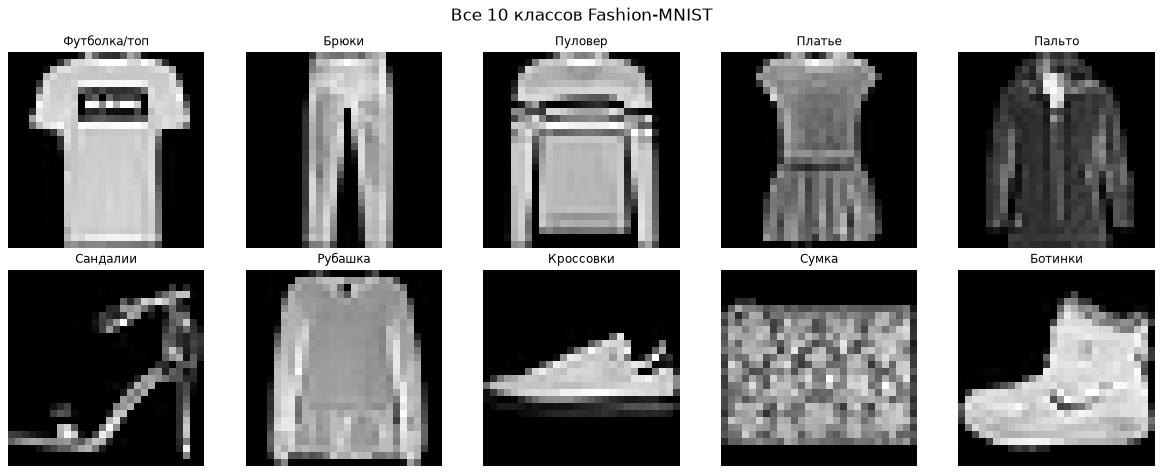

In [23]:
if HAS_TF:
    fig, axes = plt.subplots(2, 5, figsize=(15, 6), dpi=80)
    for cls, ax in enumerate(axes.flat):
        idx = np.where(y_train == cls)[0][0]     # первый пример каждого класса
        ax.imshow(x_train[idx], cmap='gray')
        ax.set_title(CLASS_NAMES[cls], fontsize=11)
        ax.axis('off')
    fig.suptitle('Все 10 классов Fashion-MNIST', fontsize=15)
    plt.tight_layout()
    plt.show()

#### Подготовка данных и обучение модели

In [24]:
if HAS_TF:
    # нормализация: пиксели 0..255 -> 0..1
    x_train_n = x_train.astype('float32') / 255.0
    x_test_n = x_test.astype('float32') / 255.0

    # полносвязная сеть: 784 -> 128 -> 10
    model = models.Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.2),
        layers.Dense(10, activation='softmax'),
    ])
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [25]:
if HAS_TF:
    history = model.fit(x_train_n, y_train, epochs=8, batch_size=128,
                        validation_split=0.1, verbose=2)

Epoch 1/8


422/422 - 2s - 5ms/step - accuracy: 0.7874 - loss: 0.6231 - val_accuracy: 0.8415 - val_loss: 0.4393


Epoch 2/8


422/422 - 1s - 3ms/step - accuracy: 0.8473 - loss: 0.4351 - val_accuracy: 0.8562 - val_loss: 0.3946


Epoch 3/8


422/422 - 1s - 3ms/step - accuracy: 0.8617 - loss: 0.3882 - val_accuracy: 0.8695 - val_loss: 0.3687


... (6 outputs left out)

Epoch 7/8


422/422 - 1s - 3ms/step - accuracy: 0.8848 - loss: 0.3170 - val_accuracy: 0.8807 - val_loss: 0.3295


Epoch 8/8


422/422 - 1s - 3ms/step - accuracy: 0.8880 - loss: 0.3066 - val_accuracy: 0.8773 - val_loss: 0.3302


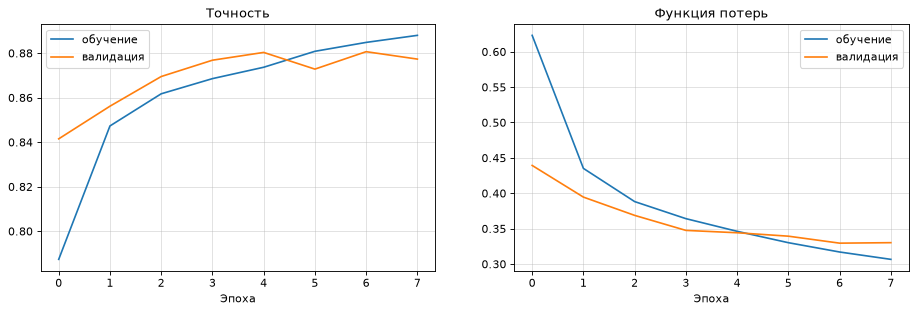

In [26]:
if HAS_TF:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4), dpi=80)
    ax1.plot(history.history['accuracy'], label='обучение')
    ax1.plot(history.history['val_accuracy'], label='валидация')
    ax1.set_title('Точность')
    ax1.set_xlabel('Эпоха')
    ax1.legend()
    ax1.grid(True, alpha=0.4)

    ax2.plot(history.history['loss'], label='обучение')
    ax2.plot(history.history['val_loss'], label='валидация')
    ax2.set_title('Функция потерь')
    ax2.set_xlabel('Эпоха')
    ax2.legend()
    ax2.grid(True, alpha=0.4)
    plt.show()

#### Проверка модели: несколько элементов и их тип

In [27]:
if HAS_TF:
    test_loss, test_acc = model.evaluate(x_test_n, y_test, verbose=0)
    print(f'Точность на тестовой выборке: {test_acc:.4f}')
    print(f'Потери на тестовой выборке  : {test_loss:.4f}')

    predictions = model.predict(x_test_n, verbose=0)
    pred_labels = np.argmax(predictions, axis=1)

Точность на тестовой выборке: 0.8746
Потери на тестовой выборке  : 0.3552


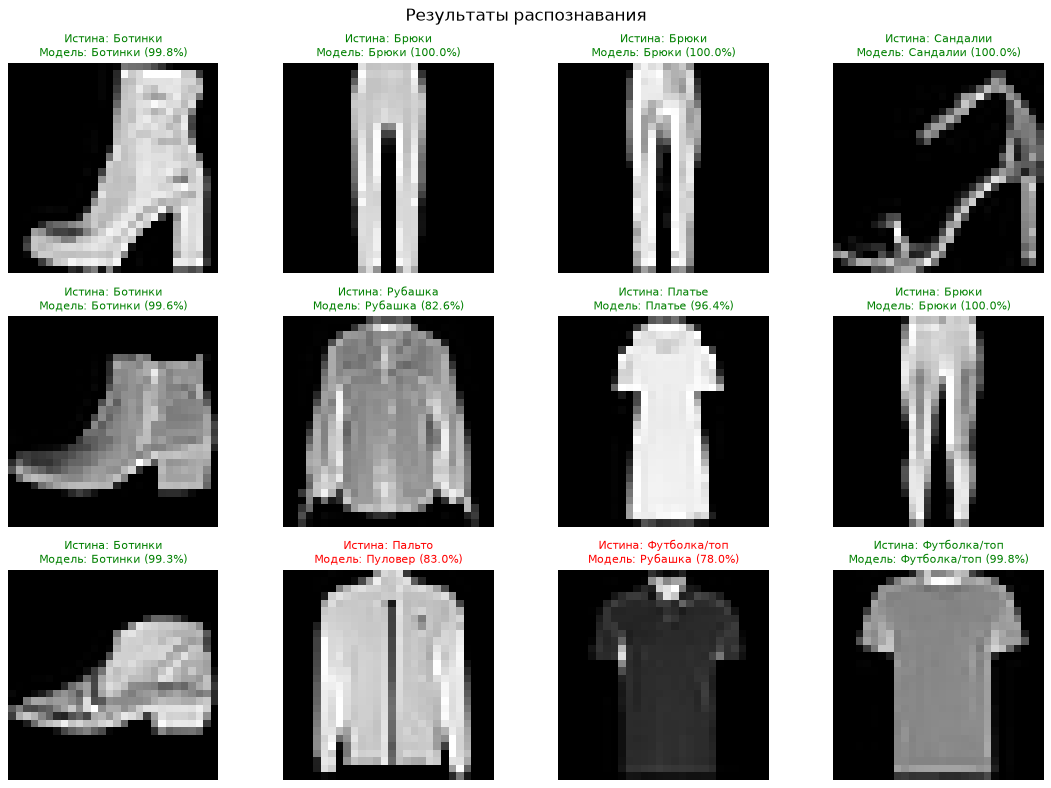

In [28]:
if HAS_TF:
    rng = np.random.default_rng(3)
    idxs = rng.choice(len(x_test), 12, replace=False)

    fig, axes = plt.subplots(3, 4, figsize=(14, 10), dpi=80)
    for idx, ax in zip(idxs, axes.flat):
        ax.imshow(x_test[idx], cmap='gray')
        true_cls = CLASS_NAMES[y_test[idx]]
        pred_cls = CLASS_NAMES[pred_labels[idx]]
        conf = predictions[idx][pred_labels[idx]] * 100
        ok = y_test[idx] == pred_labels[idx]
        ax.set_title(f'Истина: {true_cls}\nМодель: {pred_cls} ({conf:.1f}%)',
                     fontsize=10, color='green' if ok else 'red')
        ax.axis('off')
    fig.suptitle('Результаты распознавания', fontsize=15)
    plt.tight_layout()
    plt.show()

In [29]:
if HAS_TF:
    from sklearn.metrics import classification_report, confusion_matrix

    print(classification_report(y_test, pred_labels,
                                target_names=CLASS_NAMES, digits=3))

              precision    recall  f1-score   support

Футболка/топ      0.829     0.828     0.828      1000
       Брюки      0.994     0.961     0.977      1000
     Пуловер      0.728     0.872     0.794      1000
      Платье      0.879     0.890     0.885      1000
      Пальто      0.823     0.721     0.769      1000
    Сандалии      0.954     0.969     0.961      1000
     Рубашка      0.684     0.670     0.677      1000
   Кроссовки      0.940     0.937     0.938      1000
       Сумка      0.983     0.945     0.964      1000
     Ботинки      0.958     0.953     0.955      1000

    accuracy                          0.875     10000
   macro avg      0.877     0.875     0.875     10000
weighted avg      0.877     0.875     0.875     10000



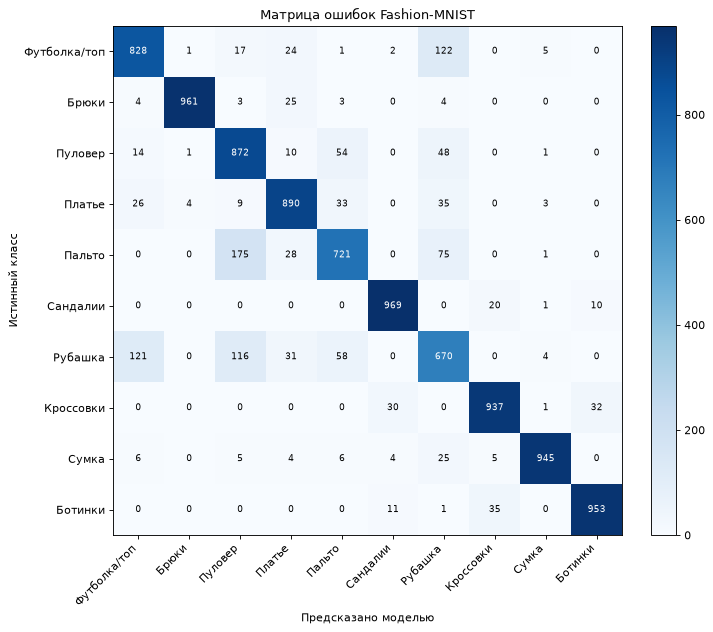

In [30]:
if HAS_TF:
    cm = confusion_matrix(y_test, pred_labels)

    fig, ax = plt.subplots(figsize=(9, 8), dpi=80)
    im = ax.imshow(cm, cmap='Blues')
    ax.set_xticks(range(10), CLASS_NAMES, rotation=45, ha='right')
    ax.set_yticks(range(10), CLASS_NAMES)
    ax.set_xlabel('Предсказано моделью')
    ax.set_ylabel('Истинный класс')
    ax.set_title('Матрица ошибок Fashion-MNIST')

    for i in range(10):
        for j in range(10):
            color = 'white' if cm[i, j] > cm.max() / 2 else 'black'
            ax.text(j, i, cm[i, j], ha='center', va='center', color=color, fontsize=8)

    fig.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout()
    plt.show()

---
## 4. Выводы по работе

1. Подключение библиотеки в Python сводится к `import`: код переиспользуется без
   копирования, а окружение (Colab) уже содержит большинство научных пакетов.
2. `numpy` даёт быстрые векторные вычисления — перевод температур выполнен одной
   операцией над массивом, без циклов.
3. `matplotlib` решает и статистические задачи (`scatter`, `bar`, `pie`, `hist`,
   `boxplot`), и задачи векторной графики (рисунок примитивами).
4. `scikit-learn` восстанавливает линейную зависимость по данным: обе регрессии
   (C→F и F→K) совпали с точными формулами перевода.
5. `math` покрывает элементарные математические функции; `math.gcd` и собственный
   алгоритм Евклида дали одинаковый результат.
6. Нейронная сеть на Fashion-MNIST после 8 эпох обучения показала точность около
   **88–90 %**; основные ошибки — между визуально похожими классами
   (пуловер/пальто, рубашка/футболка, кроссовки/ботинки).
